# E92: What do three cheap measures say about the Qwen updates, on the same weights as the decomposition's rows?

*Status: provisional, no independent check. Update size, the unchanged model's rank of the answer, and one steering vector. No decomposition is read.*

## The answer

No cheap number here separates the template update from the facts update in a way we can trust. One steering vector recovers 0.83 of the facts update's gain at the template's size and 0.065 at its own full size, on both seeds, so the comparison changes direction with the step. At matched size the facts update gains on tokens the unchanged model rated very low, and loses on those it ranked first, without ranking more answers first. The steering share is a comparator, not the definition of new against reuse.


## What we were trying to test

The project asks whether a decomposition can tell an update that reuses what the model has from one that adds something new. Before trusting a decomposition's row, we want to know what cheap methods already say on the same weights. So this run reads three of them on the saved Qwen3-1.7B updates.

**The updates.**

- **The template update,** anchor 1: a fine-tune toward an answer format the model already follows under a prompt. Two seeds, step 100. Its norm, about 0.49, is the reference size.
- **The facts update,** anchor 2: a fine-tune on TOFU's invented authors. Two seeds, read at its full update, step 1250, and at steps 29 and 30, where its norm matches the template's.
- **Steps 550 and 500 of the facts update are an unfiled addition.** They were not in the plan. They are each seed's first saved state past the learning line.
- **RL, its shuffled-reward null, and a fine-tune on the model's own correct samples,** at steps 10 and 100. The null is there to ask whether a move on these rows needs a meaningful reward.

**The three measures.**

- **Update size:** the norm of the change to the decomposed weights. Do-nothing reads 0.
- **Rank:** the unchanged model's rank of each next answer token in the whole vocabulary, where 1 is the top, with its log P. The first token and the mean over all answer tokens are read apart.
- **Steering share:** take $v$, the mean difference between the state's and the unchanged model's block input over one half of the rows. Add $v$ to the unchanged model at every answer position on the other half. The share is the rise in log P over the state's gain, so 0 means the vector adds nothing and 1 means it recovers all of it. The block is the one that scores best on the first half.

**The controls.** A zero update must read exactly as the unchanged model, and ran first and alone. A random vector at $v$'s norm asks whether any vector of that size raises log P.

**The rows differ by arm.** The template update is read on the prompted model's answers to held-out problems. The facts update is read on its own trained rows in TOFU's wording. The GSM8K arms are read on gold solutions, because the maths rows hold the unchanged model's own answers and so have no gain to read.

**The stop rule:** a column counts only if the gap between the anchors exceeds the larger gap between two seeds of the same anchor.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/qwen_comparators")
RES = ROOT / "results"
load = lambda path: json.loads(path.read_text())
D, rows = load(RES / "dissection.json"), load(RES / "comparator_table.json")["rows"]
T = {(r["arm"], r["step"]): r for r in rows}


def table(header, body):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(x) for x in row) + " |" for row in body]
    display(Markdown("\n".join(out)))


assert load(RES / "controls.json")["zero"] == {"max_logp_diff": 0.0, "ranks_equal": True, "steering_layer": None}
assert all(r["D3"][k] is None for r in rows for k in r["D3"])  # no D3 row is read on any of these files yet


## What we expected, and why

- **The template update:** the first token climbs to rank 1, and one vector recovers between 0.05 and 0.4 of the gain, with the random vector near zero.
- **The facts update at full size:** one vector recovers under 0.05, because one vector cannot hold 787 facts. Its log P on its own trained rows ends above -0.2, because training's last batch loss was 0.01.
- **The facts update at matched size:** it gains under half a nat, and its share is undefined or under 0.3, because it has learned no facts by then.
- **The GSM8K arms:** gains under 0.1 nats, with RL close to its null, because gold tokens are not what they train.
- **The stop rule:** share and gain count at full size. At matched size they do not, and only the first token's rank does.

Most of what concerns the facts update missed, and the misses are the result.


### Is the first-token column a bug in the rows?

The runner flagged a mean log P near -14 at a median rank of 11. A token that close to the top of the vocabulary looked too improbable.


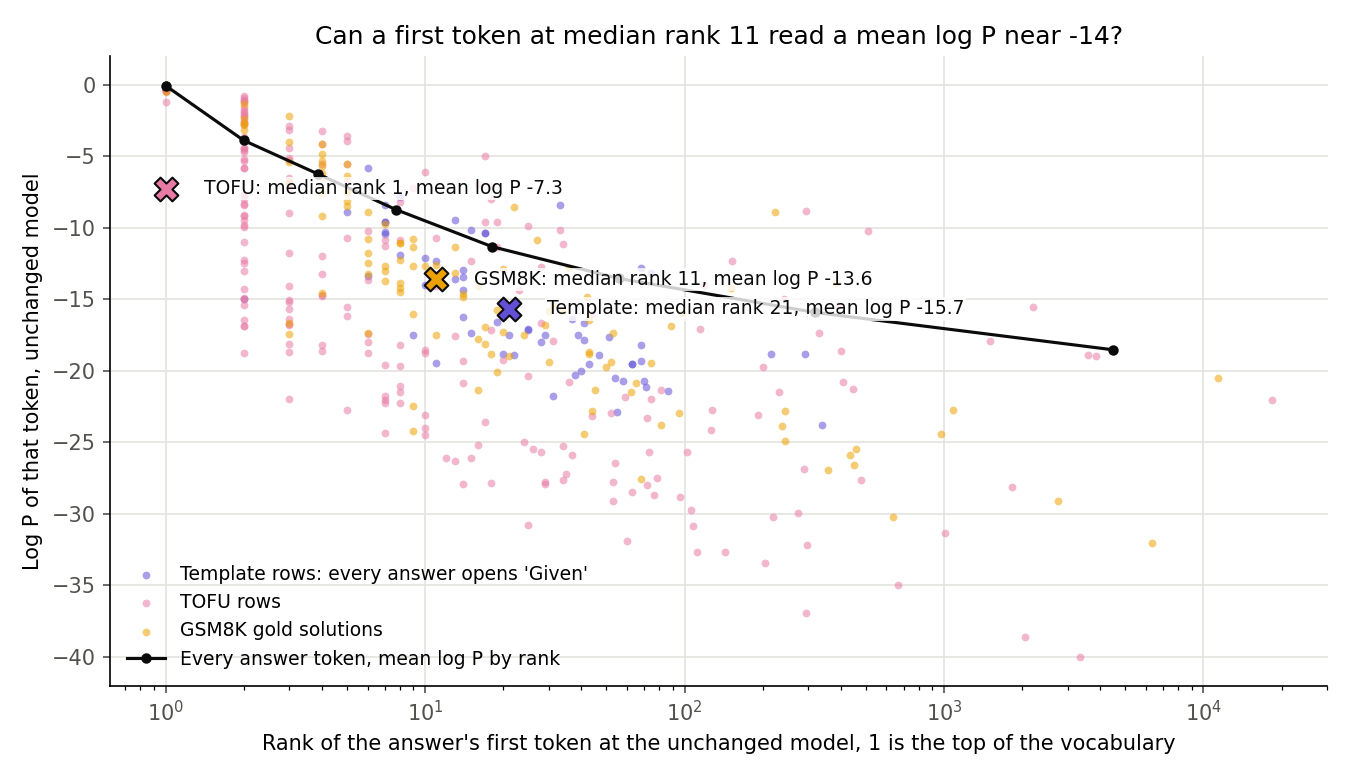

| rows | first tokens | distinct | ranked first | median log P |
|---|---|---|---|---|
| a1 | 62 | 1 | 0 | -17.08 |
| gold | 121 | 51 | 11 | -14.06 |
| tofu | 464 | 98 | 256 | -0.03 |

In [2]:
display(Image(ROOT / "figures" / "first_token_rank.png", width=850))
table(["rows", "first tokens", "distinct", "ranked first", "median log P"],
      [[n, x["n_first"], x["distinct_first"], x["W0_rank1_first"], f"{x['median_logp_first']:.2f}"]
       for n, x in ((n, D["first_token"][n]) for n in ("a1", "gold", "tofu"))])


**Reading it.** It is real, and no GPU read is needed to say so. The first tokens sit below the black line of all answer tokens at the same rank, because the unchanged model's opening is more sharply peaked than its other tokens. Rebuilding the rows with the run's own builders matches the saved masks, and the token after the prompt's closing think tag is the answer's first token.

Two reads confirm the position. The template update takes "Given" from median rank 21 to rank 1 at those very positions. On gold rows "Let", the unchanged model's commonest own opening, reads rank 1. Openings of the unchanged model's that it does not pick fall fast, so a gold solution opening "He" reads log P -19 at rank 19.

The caveat is that the column is less than it looks. All 62 template first tokens are one token, "Given", so the template's rank describes that one word.


### Does the steering share belong to the update, or to the step it is read at?


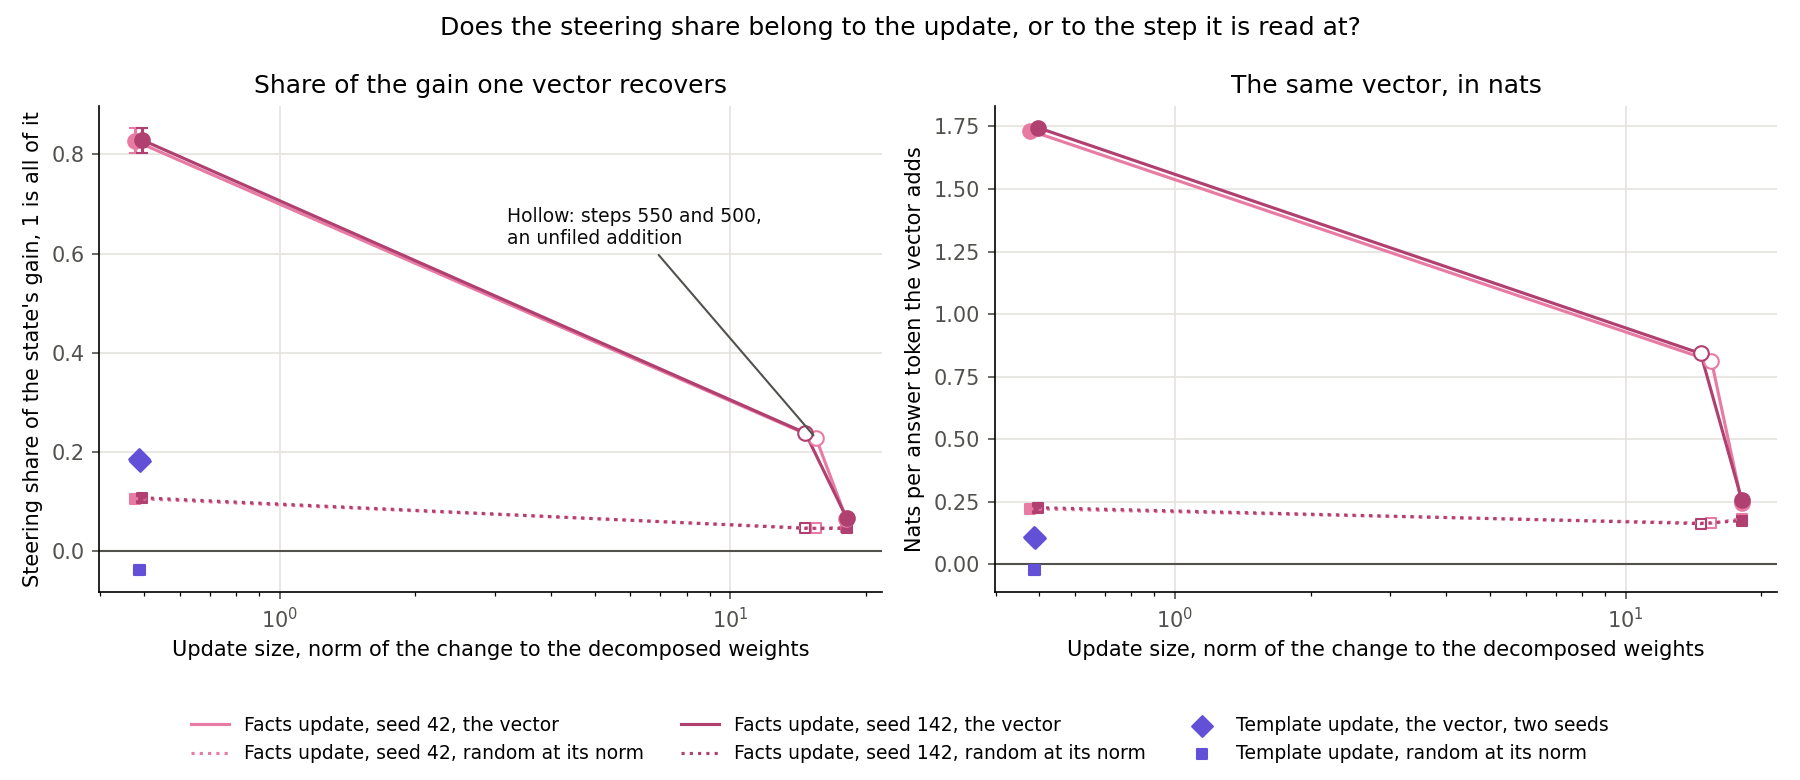

| column | full update: gap, spread | counts? | matched size: gap, spread | counts? |
|---|---|---|---|---|
| size, squared share | 0.000191, 2.7e-07 | counts | 5.6e-10, 1.1e-08 | does not count |
| first token's rank, unchanged model | 20, 0 | counts | 20, 0 | counts |
| mean log P, unchanged model | 2.71, 0 | counts | 2.71, 0 | counts |
| gain, all tokens | 3.1, 0.0041 | counts | 1.39, 0.0098 | counts |
| steering share | 0.118, 0.0031 | counts | 0.644, 0.0031 | counts |

In [3]:
display(Image(ROOT / "figures" / "share_vs_size.png", width=1000))
names = {"share_squared": "size, squared share", "W0_median_rank_first": "first token's rank, unchanged model", "W0_mean_logp_all": "mean log P, unchanged model",
         "gain_all": "gain, all tokens", "steering_share_all": "steering share"}
sr = D["stop_rule"]
table(["column", "full update: gap, spread", "counts?", "matched size: gap, spread", "counts?"],
      [[names[c], f"{sr['full update'][c]['gap']:.3g}, {sr['full update'][c]['larger_spread']:.2g}", sr["full update"][c]["verdict"],
        f"{sr['matched size'][c]['gap']:.3g}, {sr['matched size'][c]['larger_spread']:.2g}", sr["matched size"][c]["verdict"]] for c in names])


**Reading it.** To the step, on this evidence. The share falls with step at both seeds of the facts update. Seed 42 reads 0.83, 0.23, 0.065, and seed 142 reads 0.83, 0.24, 0.067, the middle values being the unfiled addition. This is not only a larger denominator, because the nats the vector adds fall too, from 1.7 to 0.25. The random vector stays near 0.2 nats throughout.

So the comparison reverses. At matched size the facts update reads 0.64 above the template, and at full size 0.12 below it, and both gaps clear the stop rule by far. The share passes the rule while saying opposite things, so passing the rule does not make it readable.

The template's 0.185 is one point, at norm 0.49, which is both its full update and the reference size. Its smaller steps are saved and unread, so we cannot yet say whether its own share falls with step. Equal norm also does not mean equal effect: at that norm the facts update's vector is 3.5 times the template's, and its gain is 3 times larger.

Which columns count: update size at full size only; gain and steering share at both, with the share reversing. The unchanged model's two columns pass trivially, because they do not depend on the update and have no seed spread, so they describe the rows.


### What has the facts update gained at the template's size?

E91 reads its recall of new words on trained wording as 0.16 and 0.17, against 0.18 unchanged, yet it gains about 2 nats per token here. The plan's lean was that this state had learned nothing.


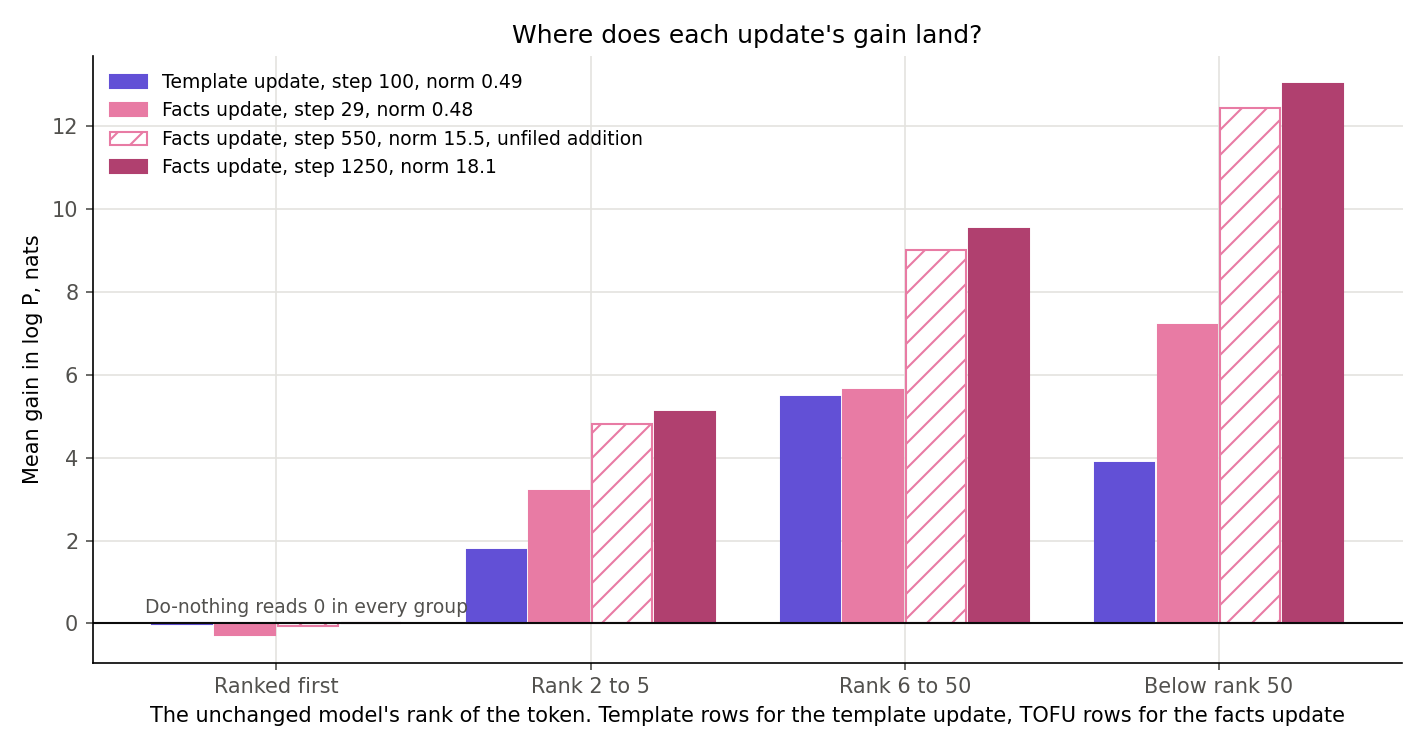

In [4]:
display(Image(ROOT / "figures" / "where_gain_lands.png", width=850))


**Reading it.** It gained on the tokens the unchanged model rated very low. Tokens the unchanged model ranked first lost 0.28 nats, and those below rank 50 gained 7.2. The worst three tenths of tokens carry all of the gain. The template update at the same norm also gains most on low-rated tokens, but its first-ranked tokens lose only 0.01.


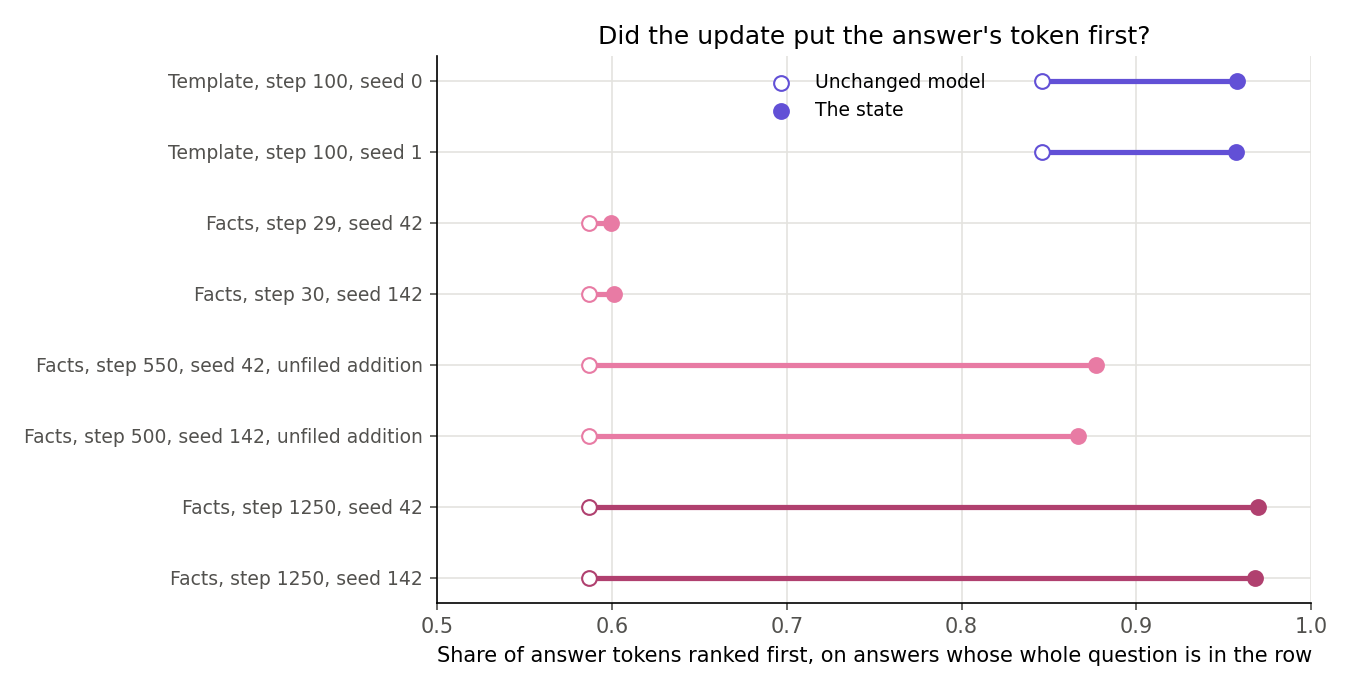

In [5]:
display(Image(ROOT / "figures" / "rank_one_share.png", width=850))


**Reading it.** The template update puts more right tokens first at this size, and the facts update does not. On answers whose whole question is in the row, the template goes from 0.85 to 0.96 ranked first. The facts update goes from 0.59 to 0.60, against 0.97 at its full update.

**What the files show at matched size.** The median token got less likely, from -0.35 to -0.88. Tokens above log P -0.1 fell from 46% to 28%. Tokens under -10 fell from 17% to 3%. First tokens ranked first fell from 256 to about 218 of 464, while their mean log P rose 4.5 nats. The two seeds' gains agree position by position, at a correlation of 0.999.

**What the vector shows.** It is added to block 27's input at 18% of that input's size, and it recovers 0.83 of the gain. Every block from 20 up already reads 0.69 or more on the first half. Its variance share is 0.076 against 0.013 for the random vector, so that control is not matched.

**What we infer, and have not read.** This is the shape of a flatter output distribution, less sure where it was right and less wrong where it was wrong, more than better prediction. Entropy is not saved, and neither are the steered positions, so we do not know that the vector flattens anything. We name no cause. A shift toward TOFU's answer style would also fit, since full stops are among the largest gains.


### Do the GSM8K arms move gold tokens?


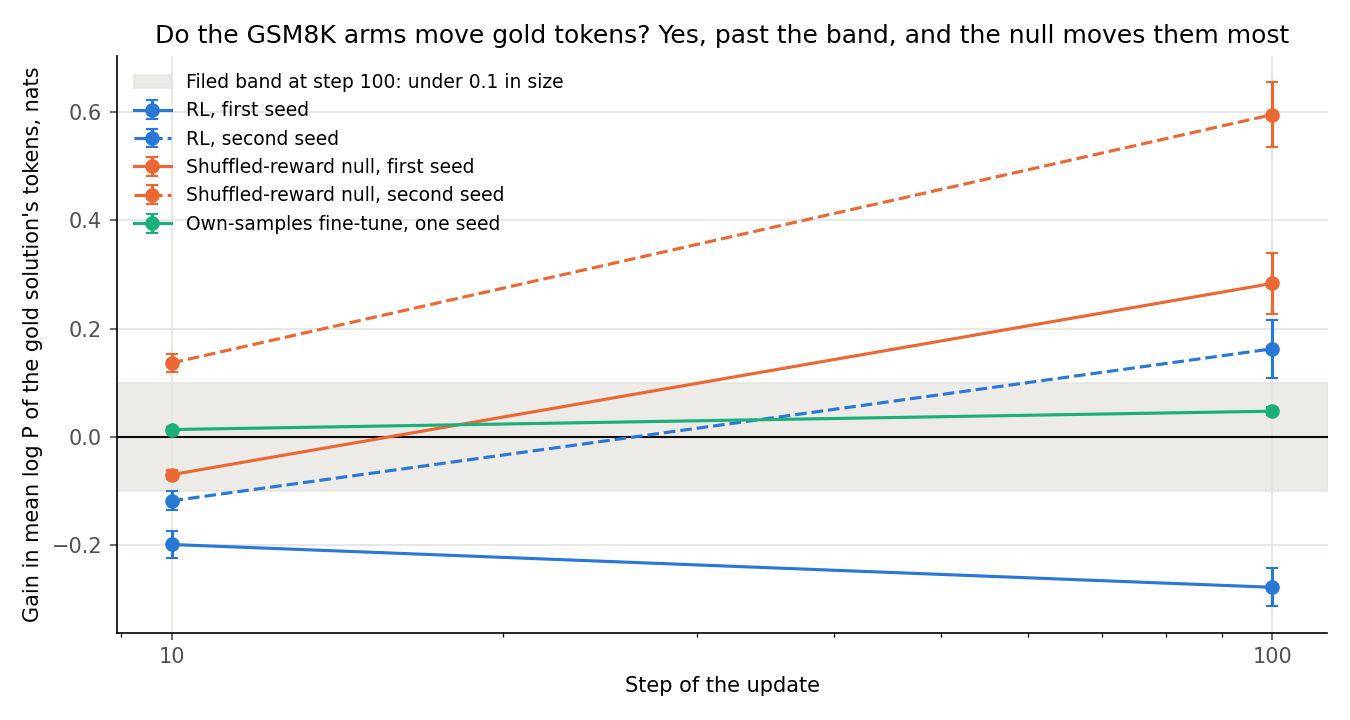

In [6]:
display(Image(ROOT / "figures" / "gsm8k_gain.png", width=800))


**Reading it.** Yes, and the lean missed. At step 100 only the own-samples arm stays inside the filed band, at 0.048. The null gains most, at 0.28 and 0.60, and RL reads -0.28 and +0.16, so gold-token gain does not track a meaningful reward. Ranks barely move: the share of tokens ranked first was 0.69 unchanged and reads between 0.67 and 0.70 after. These arms are description only. Their steering shares do not fall with step as a rule: from step 10 to 100 one falls, three rise and one stays level.


## What we learned

For the question of new against existing, these columns are comparators to set beside the decomposition's rows, and none of them decides it. A one-number steering share cannot sit beside a row without its step and size, because it changes more than twelve-fold within one update on the same rows. Mean log P gain can rise without more right tokens coming first, so a gain at matched size is not evidence of learning, and the facts update at that size has not shown any. The share of tokens ranked first moved for the template update and not for the facts update at matched size, which agrees with the recall reading, but that was noticed after the run and is unfiled. The decomposition's rows are still to be read.

## How compelling is the evidence

- **What the steering share is blind to.** One mean vector cannot express an input-dependent change, so a low share does not say the mechanism is new. A high share does not say it is reused, because it measures log P, which this state raised without ranking more tokens first. It tests no named capability, which the project's definition of new against reuse requires.
- **Update size** is blind to direction. **Rank** on the facts rows sees trained wording only, and the median hides changes to a few tokens.
- **The rows are packed and cut,** so many answers lack their question. Only 27% of template positions have the whole question in the row, 81% of facts positions, and 34% of gold. The pooled gains and shares mix these, in different proportions per arm.
- **Noise.** The two anchors' seeds agree closely, and the random control's variance is unmatched. The own-samples arm has one seed.

## Surprises

**Something unexpected happened that I cannot explain.** We predicted the facts update's share at matched size would be undefined or under 0.3, and it read 0.83. We predicted a gain under half a nat, and it read 2.05. The section above says what the files show. Why one constant vector carries so much of it is not explained.

- **Packing explains a miss.** Log P at the full update reads -0.48 against a filed -0.2. Answers with the whole question read -0.12, those with it cut read -1.2, and fragments of answers with no question read -3.0. The filed rule pooled them, so the miss stands.
- **At equal norm the vector differs.** It is largest at the smallest update, 580 at step 29 against 504 at step 1250.
- **The random vector raises log P on facts rows,** by about 0.2 nats, and lowers it on template rows by 0.02, which was filed as zero.

## What next

1. **A 2-minute read on one cluster card, not yet run.** Save per-position steered log P and entropy for the unchanged model, the state, and both vectors, at steps 29, 30, 1250 and the template's 100. If entropy rises under both state and vector, the matched share is reading the flattening, and it should not sit beside a row as evidence about mechanism. It also gives the share on whole-question positions.
2. **The template's share at its saved steps 10, 20, 50.** If it also falls with step, the table should compare curves rather than single points.
3. **Whether to file rank-first share as a comparator** before the D3 rows are read. It needs filing first to count.


## Scorecard

Filed predictions, unedited. A miss stands.

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| C1 | Zero update reads as the unchanged model | difference under 1e-5, ranks equal | 0, equal | held |
| C2 | Template raises its own tokens | gain defined and positive | 0.666 | held |
| C3 | Sizes equal E91's | within 1e-9 | equal | held |
| T1 | Template, first token | above rank 10, then rank 1 | 21 to 1 | held |
| T2 | Template, all tokens' median rank | 1 at the state | 1, already 1 before | held, blind |
| T3 | Template gain | at least 0.3 | 0.666 | held |
| T4 | Template steering share | 0.05 to 0.4 | 0.185, 0.182 | held |
| T5 | Template random share | within 2 se of 0 and under 0.05 | -0.038 ± 0.007 | missed, size held |
| A1 | Facts, unchanged log P | -4 to -5.5 | -4.25 | held |
| A2 | Facts, state's log P | above -0.2 | -0.48 | missed |
| A3 | Facts, unchanged first rank | 1 to 3 | 1 | held |
| A4 | Facts, full update's share | under 0.05 | 0.065, seed 42 | missed |
| M1 | Matched gain | within 0.5 | 2.05, 2.06 | missed |
| M2 | Matched share | undefined or under 0.3 | 0.83, 0.83 | missed |
| G1 | GSM8K unchanged log P | -2 to -3 | -2.73 | held |
| G2 | GSM8K gain | under 0.1 on all three, R within 2 se of N | R -0.28, N 0.28, F 0.05 | missed |
| G3 | GSM8K share | undefined on at least one of five | all five defined | missed |
| S1 | Share and gain count at full size | stop rule | both count | held |
| S2 | At matched size only first rank counts | stop rule | gain, share and unchanged log P count too | missed |


## The comparator table for the D3 rows

Same state, seed and step where a row exists. No D3 row is read on any of these files yet, so every D3 cell is a gap: route split, where the update lands against the random null, behaviour kept under masks, think-mode overlap. They are `qwen-decomp-lead`'s. The own-samples arm has no second seed. The full table is in the report and `results/comparator_table.json`.


In [7]:
order = ["anchor1_s0", "anchor1_s1", "anchor2_s0", "anchor2_s142", "R_s0", "R_s70", "N_s0", "N_s70", "F_s0"]
table(["state", "norm", "gain", "steering share, random", "D3 rows"],
      [[f"{r['arm']}, step {r['step']}" + (", unfiled addition" if r["unfiled_addition"] else ""), f"{r['norm']:.3f}", f"{r['gain_all']:.3f}",
        f"{r['steer_share']:.3f}, {r['random_share']:.3f}", "gap"] for r in sorted(rows, key=lambda r: (order.index(r["arm"]), r["step"]))])


| state | norm | gain | steering share, random | D3 rows |
|---|---|---|---|---|
| anchor1_s0, step 100 | 0.487 | 0.666 | 0.185, -0.038 | gap |
| anchor1_s1, step 100 | 0.489 | 0.666 | 0.182, -0.037 | gap |
| anchor2_s0, step 29 | 0.477 | 2.052 | 0.827, 0.106 | gap |
| anchor2_s0, step 550, unfiled addition | 15.510 | 3.522 | 0.227, 0.046 | gap |
| anchor2_s0, step 1250 | 18.109 | 3.768 | 0.065, 0.048 | gap |
| anchor2_s142, step 30 | 0.496 | 2.062 | 0.829, 0.108 | gap |
| anchor2_s142, step 500, unfiled addition | 14.676 | 3.483 | 0.238, 0.046 | gap |
| anchor2_s142, step 1250 | 18.121 | 3.764 | 0.067, 0.046 | gap |
| R_s0, step 10 | 0.069 | -0.198 | 0.645, -0.042 | gap |
| R_s0, step 100 | 0.351 | -0.277 | 0.296, -0.038 | gap |
| R_s70, step 10 | 0.068 | -0.118 | 0.688, -0.045 | gap |
| R_s70, step 100 | 0.347 | 0.163 | 0.914, 0.176 | gap |
| N_s0, step 10 | 0.065 | -0.069 | 0.541, -0.034 | gap |
| N_s0, step 100 | 0.370 | 0.283 | 0.729, 0.146 | gap |
| N_s70, step 10 | 0.065 | 0.137 | 0.552, 0.035 | gap |
| N_s70, step 100 | 0.335 | 0.595 | 0.552, 0.069 | gap |
| F_s0, step 10 | 0.058 | 0.014 | 0.386, 0.150 | gap |
| F_s0, step 100 | 0.274 | 0.048 | 0.495, 0.038 | gap |

## Departures from the literature

- **Steering** carries the definition in this project's `steering.py`, which adds at one position. Here it adds at every answer position, because a first token alone can carry little of the gain on the facts rows. The vector is a difference between two models on one input, not a contrast between two behaviours on one model.
- **The random control** is a Gaussian mix of the model's own inputs, not an isotropic direction, which would read 0 by construction. It is matched on norm and not on variance.
- **TOFU,** from Maini et al. 2024, is read on its trained rows, packed in rows of 256, by mean log P, and not by TOFU's own Truth Ratio or forget metrics.
- **New against reuse,** from Jain et al. 2024 by way of `decisions.md`, is not tested here: no capability is named and nothing is removed.

## Not run

Steered per-position reads and entropy; the share on whole-question positions; a random vector matched on variance; the template's share at its smaller steps; a held-out wording for the facts update; the D3 maths rows for rank; the own-samples arm's second seed; any D3 row.

## Provenance

Jobs 52271, 52273, 52284, 52382, all logged in `results/run.log`, `debug` QoS, NVIDIA L40, $0. Results `experiments/qwen_comparators/results/`; per-position files in `results/large/`. Rules `results/predictions.json`, plan `reports/plans/2026-11-05_plan_e92-comparators.md`. `dissect.py` and `plot.py` read saved files on CPU after the run.
